# La batería de validación de cartera: prueba retrospectiva de cola, convergencia, aditividad, recursión frente a Monte Carlo, tamaño y potencia de la correlación

**Pregunta:** ¿Rechazan las cinco pruebas de la batería de cartera un modelo equivocado y aceptan uno correcto, y qué dicen sus luces sobre los cinco tipos de préstamo de Estados Unidos?

- **Nivel:** 2, El método en la práctica
- **Requisitos previos:** los notebooks 02 a 05 de este tema (el ajuste, las cópulas, CreditRisk+ y las contribuciones de Euler)
- **Tiempo de lectura:** unos 50 minutos

## Objetivos

Al terminar este notebook puedes:

- nombrar las cinco pruebas de la batería de cartera, la hipótesis nula de cada una y la regla que convierte su resultado en una luz;
- correr cada prueba en un caso que debe aceptar y en un caso que debe rechazar, y ver qué devuelve el motor en ambos;
- decir qué no puede ver cada prueba: cuán pocos años necesita la prueba retrospectiva de cola para rechazar, qué significa una prueba de convergencia en verde para una cartera pequeña, qué es una tolerancia;
- leer el tamaño y la potencia de los estimadores de correlación en la grilla del simulador, con el error estándar de Monte Carlo y el intervalo de Wilson de cada tasa;
- leer juntas las filas versionadas de los cinco tipos de préstamo y de la grilla del simulador, y decir qué concluye un validador de ellas.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este notebook, con las mismas versiones exactas:

```bash
pip install riskvalidation==1.1.0 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. La celda siguiente importa los paquetes e imprime sus versiones.

In [1]:
# Importar las herramientas e imprimir las versiones con que corren, para compararlas con notebooks/requirements.txt
import importlib.metadata as md
import json
import math
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from scipy import stats

# El cuaderno está tres carpetas por debajo de la raíz del repositorio
ROOT = Path("../../..").resolve()

for name in ("riskvalidation", "numpy", "scipy", "matplotlib",):
    print(name, md.version(name))

# Nombres de las luces de validación
LIGHTS = {"green": "verde", "amber": "ámbar", "red": "rojo", "not_evaluated": "no evaluada"}

riskvalidation 1.0.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Datos

Siete archivos del caso C10, todos versionados (propietario: este repositorio; los cinco archivos por tipo de préstamo descansan en la tabla `chgallsa` de la Reserva Federal, https://www.federalreserve.gov/releases/chargeoff/chgallsa.htm, dominio público, clase de licencia `mirror-allowed`):

- los cinco archivos por tipo de préstamo `commercial-industrial.json`, `commercial-real-estate.json`, `residential.json`, `credit-cards.json` y `other-consumer.json` en `data/derived/C10/`: cada uno trae 15 filas de `tests` (una prueba retrospectiva de cola, doce filas de aditividad de Euler, una fila de convergencia y una de CreditRisk+), los parámetros ajustados y las contribuciones detrás de esas filas;
- `grid-22.json` y `grid-40.json`: la **grilla del simulador**, el tamaño y la potencia de los estimadores de correlación sobre fracciones de incumplimiento anuales sintéticas sorteadas con una correlación conocida (`truth_status` es `synthetic-known-truth`): una PD conocida de 2%, doce correlaciones conocidas de 0,02 a 0,24, una nula de 0,12, 400 réplicas cada una, series de 22 y 40 años. Cada archivo tiene 24 filas de `portfolio.correlation_size_power`, una por correlación y estimador.

La celda siguiente los carga y cuenta las filas de prueba versionadas por prueba y luz.

In [2]:
# Cargar los siete artefactos y contar las filas de prueba versionadas por prueba y luz
NAMES = {
    "commercial-industrial": "Comerciales e industriales",
    "commercial-real-estate": "Inmobiliario comercial",
    "residential": "Inmobiliario residencial",
    "credit-cards": "Tarjetas de crédito",
    "other-consumer": "Otro consumo",
}
read = lambda name: json.loads((ROOT / "data" / "derived" / "C10" / f"{name}.json").read_text(encoding="utf-8"))
docs = {k: read(k) for k in NAMES}
grids = {22: read("grid-22"), 40: read("grid-40")}

versions = {d["provenance"]["riskvalidation_version"] for d in [*docs.values(), *grids.values()]}
print("calculado con riskvalidation", versions)
print(f"{'tipo de préstamo':26s} {'filas':>5s}")
for key, label in NAMES.items():
    print(f"{label:26s} {len(docs[key]['tests']):5d}")
for years, g in grids.items():
    print(f"grilla {years} años: {len(g['tests'])} filas; PD conocida", g["outputs"]["generator"]["known_pd"])

calculado con riskvalidation {'1.0.1'}
tipo de préstamo           filas
Comerciales e industriales    15
Inmobiliario comercial        15
Inmobiliario residencial      15
Tarjetas de crédito           15
Otro consumo                  15
grilla 22 años: 24 filas; PD conocida 0.02
grilla 40 años: 24 filas; PD conocida 0.02


## Método

### Paso 1: la prueba retrospectiva de cola, y cuán pocos años necesita para rechazar

**H0:** el número de años de evaluación sobre el cuantil $q$ ajustado es Binomial$(n, 1-q)$; la alternativa es más años sobre él que lo que dice el ajuste. El valor p es la cola superior $P(X\ge\text{observado})$ al nivel primario de 99% (Vasicek, 2002; Gordy, 2003, https://doi.org/10.1016/S1042-9573(03)00040-8). **Luz:** verde cuando $p\ge0{,}05$, ámbar de 0,01 a 0,05, roja bajo 0,01, una puerta interna de Contraste y no un umbral regulatorio. Con $n=6$ años de evaluación la prueba tiene poca potencia al 99%: un solo año sobre el cuantil da $p=1-0{,}99^6=0{,}0585$, todavía verde. La celda siguiente toma la PD y la correlación ajustadas de los préstamos comerciales e industriales del artefacto y entrega a `tail_backtest` del motor tres series de seis años que construye: todos bajo el cuantil 99%, un año sobre él y dos años sobre él. Luego corre los años de evaluación reales de dos tipos de préstamo.

In [3]:
# Correr la prueba retrospectiva de cola en series construidas y en dos tipos reales
from riskvalidation.engines.vasicek import lhp_quantile
from riskvalidation.validation.portfolio import tail_backtest

ml = {k: d["outputs"]["fit"]["maximum_likelihood"] for k, d in docs.items()}
pd_ci, rho_ci = ml["commercial-industrial"]["pd"]["estimate"], ml["commercial-industrial"]["rho"]["estimate"]
q99 = float(lhp_quantile(0.99, pd_ci, rho_ci))
print("cuantil 99% ajustado de los préstamos comerciales:", round(q99, 5))

levels = (0.95, 0.99, 0.999)
p_by_count, light_by_count = [], []
for years_above in range(7):
    series = np.full(6, 0.004)
    series[:years_above] = 1.1 * q99
    res = tail_backtest(series, pd_ci, rho_ci, levels=levels, primary_level=0.99)
    p_by_count.append(res.p_value)
    light_by_count.append(res.light.value)
    print(f"{years_above} años sobre: p {res.p_value:.4g} | {LIGHTS[res.light.value]}")

for key in ("commercial-industrial", "residential"):
    rows = docs[key]["outputs"]["annual_rates"]
    evaluation = [r["loss_rate"] for r in rows if r["window"] == "evaluation"]
    realised = np.array([np.nan if v is None else v for v in evaluation])
    pd_k, rho_k = ml[key]["pd"]["estimate"], ml[key]["rho"]["estimate"]
    res = tail_backtest(realised, pd_k, rho_k, levels=levels, primary_level=0.99)
    print(f"{NAMES[key]:26s} observados al 99%: {int(res.statistic)} | p {res.p_value:.2e} | {LIGHTS[res.light.value]}")

cuantil 99% ajustado de los préstamos comerciales: 0.03335
0 años sobre: p 1 | verde
1 años sobre: p 0.05852 | verde
2 años sobre: p 0.00146 | rojo
3 años sobre: p 1.955e-05 | rojo
4 años sobre: p 1.476e-07 | rojo
5 años sobre: p 5.95e-10 | rojo
6 años sobre: p 1e-12 | rojo
Comerciales e industriales observados al 99%: 0 | p 1.00e+00 | verde
Inmobiliario residencial   observados al 99%: 5 | p 5.95e-10 | rojo


La celda siguiente dibuja el valor p de la prueba retrospectiva contra el número de años sobre el cuantil 99% ajustado, coloreado por la luz.

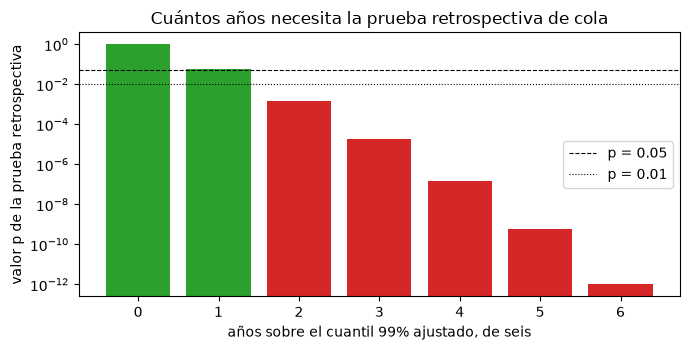

In [4]:
# Dibujar el valor p de la prueba contra el número de años sobre el cuantil 99%
colors = {"green": "tab:green", "amber": "tab:orange", "red": "tab:red"}
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.bar(range(7), p_by_count, color=[colors[v] for v in light_by_count])
ax.axhline(0.05, color="black", linestyle="--", linewidth=0.8, label="p = 0.05")
ax.axhline(0.01, color="black", linestyle=":", linewidth=0.8, label="p = 0.01")
ax.set_yscale("log")
ax.set_xlabel("años sobre el cuantil 99% ajustado, de seis")
ax.set_ylabel("valor p de la prueba retrospectiva")
ax.set_title("Cuántos años necesita la prueba retrospectiva de cola")
ax.legend()
fig.tight_layout()
plt.show()

La barra de cero años está en 1, la barra de un año queda justo sobre la línea de 0,05 y sigue verde, y desde dos años las barras caen bajo la línea de 0,01 y son rojas. Dos años malos de seis bastan para rechazar el ajuste al 99%, y uno no, de modo que la prueba es roma: no puede señalar un ajuste cuyo cuantil 99% sea algo demasiado bajo si los seis años resultan benignos. Los colores siguen las luces del motor, una puerta de Contraste y no un umbral regulatorio. La figura usa series construidas que quedan exactamente 10% sobre el cuantil; los años de evaluación reales varían en cuánto lo superan, lo que la prueba ignora, pues solo cuenta.

### Paso 2: la prueba de convergencia de Monte Carlo

**H0:** la estimación de Monte Carlo es igual al ancla analítica. El estadístico es $z=(\text{estimación}-\text{ancla})/\mathrm{ee}$ y el valor p es $2\,(1-\Phi(|z|))$, con los mismos cortes verde, ámbar y rojo. El ancla de la batería de cartera es el cuantil de la cartera grande del notebook 01, exacto solo para una cartera de muchísimos nombres idénticos: una cartera finita queda sobre él por granularidad, así que la prueba es para una cartera cercana al límite y no es un veredicto sobre una cartera real. Un error estándar no positivo o una entrada no finita da `not_evaluated`, nunca un número. La celda siguiente entrega a `mc_convergence` la estimación, el error estándar y el ancla de la fila de convergencia del caso con la estimación movida 0,5, 2,3 y 3,5 errores estándar, y con un error estándar cero.

In [5]:
# Correr la prueba de convergencia con estimaciones movidas unos errores estándar y con un error estándar cero
from riskvalidation.validation.portfolio import mc_convergence

row = next(t for t in docs["commercial-industrial"]["tests"] if t["test_id"] == "portfolio.mc_convergence")
est, se, anchor = row["extras"]["estimate"], row["extras"]["se"], row["extras"]["anchor"]
print("estimación, error estándar y ancla:", f"{est:,.0f}", f"{se:,.0f}", f"{anchor:,.0f}")

shifts = np.linspace(0.0, 4.0, 41)
p_shift = [mc_convergence(anchor + s * se, se, anchor, "var").p_value for s in shifts]
for shift in (0.5, 2.3, 3.5):
    res = mc_convergence(anchor + shift * se, se, anchor, "var")
    print(f"estimación movida {shift} errores estándar:")
    print(f"    z {res.statistic:.2f} | p {res.p_value:.4f} | {LIGHTS[res.light.value]}")
res = mc_convergence(est, 0.0, anchor, "var")
print("error estándar cero:", LIGHTS[res.light.value], "| p:", res.p_value)

estimación, error estándar y ancla: 2,286,000 23,604 2,298,834
estimación movida 0.5 errores estándar:
    z 0.50 | p 0.6171 | verde
estimación movida 2.3 errores estándar:
    z 2.30 | p 0.0214 | ámbar
estimación movida 3.5 errores estándar:
    z 3.50 | p 0.0005 | rojo
error estándar cero: no evaluada | p: None


La celda siguiente dibuja el valor p de la prueba de convergencia contra el desplazamiento de la estimación en errores estándar, con los cortes ámbar y rojo.

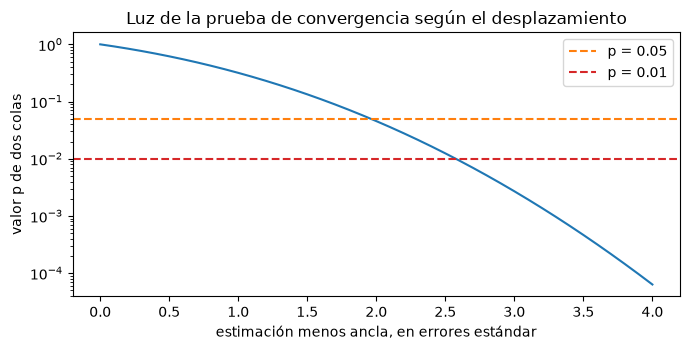

In [6]:
# Dibujar el valor p de convergencia contra el desplazamiento de la estimación
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.semilogy(shifts, p_shift, color="tab:blue")
ax.axhline(0.05, color="tab:orange", linestyle="--", label="p = 0.05")
ax.axhline(0.01, color="tab:red", linestyle="--", label="p = 0.01")
ax.set_xlabel("estimación menos ancla, en errores estándar")
ax.set_ylabel("valor p de dos colas")
ax.set_title("Luz de la prueba de convergencia según el desplazamiento")
ax.legend()
fig.tight_layout()
plt.show()

La curva cruza la línea ámbar a cerca de dos errores estándar y la línea roja a cerca de 2,6, de modo que la prueba tolera un desplazamiento de dos pasos del tamaño del ruido y rechaza más allá. Es simétrica por construcción: una estimación bajo el ancla por la misma cantidad da el mismo p. La prueba no dice por qué una estimación está lejos del ancla, si el Monte Carlo está mal, la cartera es muy pequeña para el límite o el error estándar está subestimado, y por eso el notebook 03 la encontró roja con carteras pequeñas. Un error estándar cero o negativo no da ningún valor p, así que la curva calla donde calla el motor.

### Paso 3: la aditividad de Euler, y qué es una tolerancia

**H0:** las contribuciones de Euler suman el total. El estadístico es la suma, la métrica es $|\text{suma}-\text{total}|/|\text{total}|$ y no hay valor p (una asignación suma o no suma, así que no hay ámbar): verde cuando la métrica es a lo más la tolerancia, roja sobre ella (Tasche, 2008, https://arxiv.org/abs/0708.2542). La **tolerancia es el parámetro de la prueba**, y se declara con el resultado: $10^{-6}$ para las contribuciones al ES, que suman por construcción, y 0,01 para las contribuciones al VaR por núcleo, que tienen sesgo en el borde. Un total cero da `not_evaluated`. La celda siguiente toma las contribuciones al ES versionadas de la cópula gaussiana de un factor al 99,9% y las prueba como están, luego con una contribución inflada en 0,5% y en 2%, y luego con una brecha de $10^{-4}$ bajo ambas tolerancias.

In [7]:
# Correr la prueba de aditividad con las contribuciones al ES, con otras infladas y bajo las dos tolerancias
from riskvalidation.validation.portfolio import euler_additivity

euler_blocks = docs["commercial-industrial"]["outputs"]["euler"]
block = next(b for b in euler_blocks if b["rung_method"] == "gaussian-copula-one-factor")
level = next(lv for lv in block["levels"] if lv["level"] == 0.999)
rc_es = np.array([r["rc_es"] for r in level["rows"]])
total = level["es_total"]

res = euler_additivity(rc_es, total, 1e-6)
print("contribuciones:", f"{rc_es.sum():,.2f}", "| total:", f"{total:,.2f}")
print("brecha:", f"{res.metric:.1e}", "|", LIGHTS[res.light.value])
for factor in (1.005, 1.02):
    inflated = rc_es.copy()
    inflated[0] *= factor
    res = euler_additivity(inflated, total, 0.01)
    print(f"primera contribución x {factor}: brecha {res.metric:.4f} | tolerancia 0.01: {LIGHTS[res.light.value]}")
small_gap = rc_es * (1 + 1e-4)
for tol in (0.01, 1e-6):
    res = euler_additivity(small_gap, total, tol)
    print(f"todas las contribuciones x 1,0001, tolerancia {tol:g}: brecha {res.metric:.1e} | {LIGHTS[res.light.value]}")
res = euler_additivity(rc_es, 0.0, 1e-6)
print("total cero:", LIGHTS[res.light.value], "| métrica:", res.metric)

contribuciones: 3,683,187.00 | total: 3,683,187.00
brecha: 0.0e+00 | verde
primera contribución x 1.005: brecha 0.0028 | tolerancia 0.01: verde
primera contribución x 1.02: brecha 0.0111 | tolerancia 0.01: rojo
todas las contribuciones x 1,0001, tolerancia 0.01: brecha 1.0e-04 | verde
todas las contribuciones x 1,0001, tolerancia 1e-06: brecha 1.0e-04 | rojo
total cero: no evaluada | métrica: None


### Paso 4: la recursión de CreditRisk+ frente a Monte Carlo

**H0:** la distribución de la recursión es la distribución de la muestra de Monte Carlo del mismo modelo. El estadístico es la distancia de Kolmogorov $D=\max_n|F_{\text{pmf}}(n)-F_{\text{MC}}(n)|$ y el valor p viene de la ley asintótica de Kolmogorov, $2\sum_{j\ge1}(-1)^{j-1}e^{-2j^2SD^2}$ (conservadora para una distribución discreta); la prueba es roja sea cual sea el valor p si alguna probabilidad de la recursión es negativa, y `not_evaluated` para menos de 10 escenarios o una muestra sobre la grilla. Reconstruimos el insumo de la recursión del notebook 04 y su muestra (100.000 escenarios), la probamos, y luego la rompemos dos veces: una recursión corrida con una varianza Gamma 50% demasiado alta (un modelo equivocado, que la prueba debe rechazar), y una copia de las probabilidades correctas con una entrada puesta ligeramente negativa (que la prueba debe marcar en rojo aunque su valor p no se mueva).

In [8]:
# Probar la recursión con una muestra, una varianza Gamma equivocada y una entrada negativa
from riskvalidation.portfolio import creditrisk_plus as cr
from riskvalidation.validation.portfolio import crp_recursion_vs_mc

ci_out = docs["commercial-industrial"]["outputs"]
book = ci_out["portfolio"]
crp = next(r for r in ci_out["rungs"] if r["id"] == "c4-creditrisk-plus")
sigma2 = next(p["value"] for p in crp["parameters"] if p["name"] == "sigma2")
loss_unit = next(p["value"] for p in crp["parameters"] if p["name"] == "loss_unit")
n_max = int(next(d["value"] for d in crp["diagnostics"] if d["name"] == "n_max"))
ead = np.concatenate([np.full(g["n_names"], g["ead_each"]) for g in book["groups"]])
pd_names = np.concatenate([np.full(g["n_names"], g["pd"]) for g in book["groups"]])
units = np.rint(ead * book["lgd_mean"] / loss_unit).astype(int)
base = dict(
    nu=units, pd=pd_names, w0=np.zeros(ead.size), weights=np.ones((ead.size, 1)),
    loss_unit=loss_unit, currency=book["currency"])
pmf = cr.pmf_stable(cr.CreditRiskPlusInput(sigma2=np.array([sigma2]), **base), n_max)
wrong = cr.pmf_stable(cr.CreditRiskPlusInput(sigma2=np.array([1.5 * sigma2]), **base), n_max)
broken = pmf.copy()
broken[5] = -1e-6
print("largo de grilla:", n_max, "| sigma^2:", sigma2)
print("masa en la grilla, correcta y varianza equivocada:", round(float(pmf.sum()), 6), round(float(wrong.sum()), 6))

largo de grilla: 12728 | sigma^2: 0.552065603
masa en la grilla, correcta y varianza equivocada: 1.0 1.0


La celda siguiente sortea 100.000 escenarios del modelo Poisson-Gamma con la semilla del caso y prueba contra ellos las tres versiones de la recursión.

In [9]:
# Sortear los escenarios del modelo y probar las tres versiones de la recursión
rng = np.random.default_rng(np.random.PCG64(4006))
factor = rng.gamma(shape=1.0 / sigma2, scale=sigma2, size=100_000)
sample = np.zeros(factor.size, dtype=np.int64)
first = 0
for g in book["groups"]:
    sample += int(units[first]) * rng.poisson(g["n_names"] * g["pd"] * factor)
    first += g["n_names"]

cases = (
    ("la recursión correcta", pmf),
    ("varianza Gamma x 1,5", wrong),
    ("una entrada negativa", broken),
)
for label, p in cases:
    res = crp_recursion_vs_mc(p, sample)
    print(f"{label:30s} D {res.statistic:.5f} | p {res.p_value:.3e} | {LIGHTS[res.light.value]}")
    print(f"{'':30s} entradas negativas: {res.extras['negative_entries']}")

la recursión correcta          D 0.00398 | p 8.429e-02 | verde
                               entradas negativas: 0
varianza Gamma x 1,5           D 0.06677 | p 0.000e+00 | rojo
                               entradas negativas: 0
una entrada negativa           D 0.00398 | p 8.416e-02 | rojo
                               entradas negativas: 1


### Paso 5: el tamaño y la potencia de los estimadores de correlación

La última prueba es de otro tipo: evalúa un estimador, no un modelo. En la grilla del simulador, cada una de 400 réplicas sortea una serie de fracciones de incumplimiento anuales con una correlación conocida, estima la correlación con cada uno de los dos estimadores del notebook 02, y rechaza H0: $\rho=0{,}12$ cuando 0,12 queda fuera del intervalo al 95% del estimador. Con la correlación conocida 0,12 la tasa de rechazo es el **tamaño**, que debe ser igual al $\alpha=0{,}05$ nominal; con cualquier otra correlación conocida es la **potencia**. `correlation_size_power` del motor recibe los booleanos de una celda y devuelve la tasa, su error estándar de Monte Carlo $\sqrt{\hat r(1-\hat r)/R}$ y el intervalo de Wilson al 95% (Wilson, 1927, https://doi.org/10.1080/01621459.1927.10502953). En una celda de tamaño el estadístico es $(\hat r-\alpha)/\sqrt{\alpha(1-\alpha)/R}$ con un valor p normal de dos colas; verde desde 0,05, rojo bajo 0,01. En una celda de potencia la luz es verde desde una tasa de 0,80, ámbar desde 0,50, roja bajo: puertas de Contraste. La tasa depende solo de cuántas réplicas rechazaron, así que la celda siguiente reconstruye los booleanos a partir de los conteos de la grilla y evalúa la celda de tamaño de cada estimador en la grilla de 22 años.

In [10]:
# Reconstruir los booleanos desde los conteos de la grilla y evaluar la celda de tamaño de cada estimador
from riskvalidation.validation.portfolio import correlation_size_power

gen = grids[22]["outputs"]["generator"]
print("simulador:", gen["name"], "| réplicas:", gen["n_replications"])
print("largo de serie:", gen["series_length_years"])
print("rho nula:", gen["null_rho"], "| alpha:", gen["alpha"], "| semilla:", gen["seed"])
print(f"{'estimador':20s} {'tasa':>7s} {'error est.':>10s} {'Wilson 95%':>16s} {'p':>8s} luz")
for row in grids[22]["tests"]:
    extras = row["extras"]
    if extras["role"] != "size":
        continue
    flags = np.arange(row["n"]) < row["n_events"]
    res = correlation_size_power(
        flags, extras["known_rho"], extras["null_rho"], alpha=extras["alpha"], estimator=extras["estimator"])
    interval = f"{res.extras['ci_low']:.3f}-{res.extras['ci_high']:.3f}"
    head = f"{extras['estimator']:20s} {res.metric:7.4f} {res.extras['se']:10.4f} {interval:>16s}"
    print(head, f"{res.p_value:8.2e} {LIGHTS[res.light.value]}")

simulador: vasicek-lhp-simulator | réplicas: 400
largo de serie: 22
rho nula: 0.12 | alpha: 0.05 | semilla: 7001
estimador               tasa error est.       Wilson 95%        p luz
maximum-likelihood    0.0525     0.0112      0.035-0.079 8.19e-01 verde
moments               0.1850     0.0194      0.150-0.226 3.02e-35 rojo


La grilla es la imagen completa. La celda siguiente dibuja, para las grillas de 22 y de 40 años, la tasa de rechazo de cada estimador en cada correlación conocida con su intervalo de Wilson, el nivel nominal de 5%, la puerta de potencia de 80% y la correlación nula. Donde una curva es alta la prueba ve el apartamiento de 0,12; donde es baja un validador no puede distinguir esa correlación de 0,12 con tantos años.

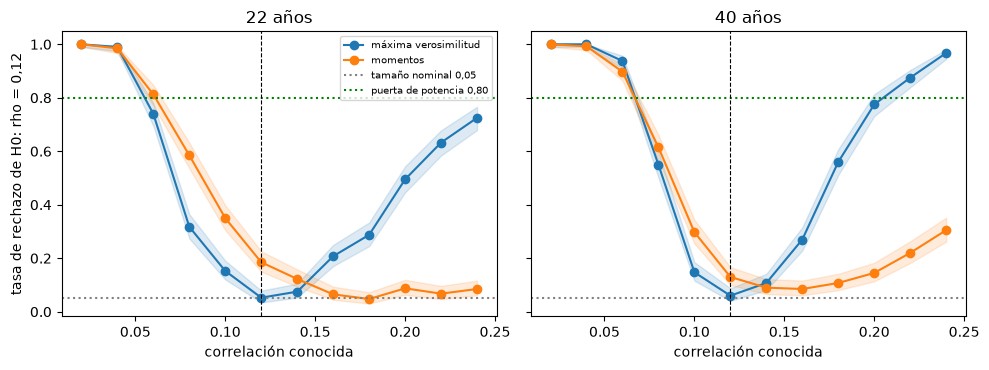

In [11]:
# Dibujar la tasa de rechazo de cada estimador contra la correlación conocida para las grillas de 22 y 40 años
estimators = (
    ("maximum-likelihood", "tab:blue", "máxima verosimilitud"),
    ("moments", "tab:orange", "momentos"),
)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)
for ax, (years, g) in zip(axes, grids.items()):
    cells = g["outputs"]["cells"]
    rho_known = np.array([c["known_rho"] for c in cells])
    for name, color, label in estimators:
        picked = [next(e for e in c["estimators"] if e["estimator"] == name) for c in cells]
        rate = np.array([e["rejection_rate"] for e in picked])
        low = np.array([e["rejection_ci_low"] for e in picked])
        high = np.array([e["rejection_ci_high"] for e in picked])
        ax.plot(rho_known, rate, marker="o", color=color, label=label)
        ax.fill_between(rho_known, low, high, color=color, alpha=0.15)
    ax.axhline(0.05, color="gray", linestyle=":", label="tamaño nominal 0,05")
    ax.axhline(0.80, color="green", linestyle=":", label="puerta de potencia 0,80")
    ax.axvline(g["outputs"]["generator"]["null_rho"], color="black", linestyle="--", linewidth=0.8)
    ax.set_xlabel("correlación conocida")
    ax.set_title(f"{years} años")
axes[0].set_ylabel("tasa de rechazo de H0: rho = 0,12")
axes[0].legend(fontsize=7)
fig.tight_layout()
plt.show()

Cada panel es la imagen completa de tamaño y potencia de un largo de serie. En la línea vertical discontinua, la nula de 0,12, una prueba honesta rechaza 5% de las veces: la curva azul toca ahí el nivel punteado de 0,05 y la naranja queda bien sobre él, en cerca de 0,19 con 22 años y 0,13 con 40. Lejos de la nula, la potencia es la altura de la curva; es alta para correlaciones muy bajo 0,12 y baja para las que están sobre ella, donde las bandas son anchas y la curva azul cruza la puerta de 0,80 solo con 40 años y solo en el borde derecho. La curva naranja, el estimador de momentos, no solo es imprecisa sino que tiene sesgo hacia abajo, así que casi nunca rechaza sobre la nula. La grilla es sintética con una verdad conocida, así que mide el estimador y nada de datos reales.

In [12]:
# Tabular las tasas de rechazo de ambos estimadores con 22 y 40 años
rates = {}
for years, g in grids.items():
    for row in g["tests"]:
        rates[(years, row["extras"]["estimator"], row["extras"]["known_rho"])] = row["metric"]

print(f"{'rho conocida':>12s} {'ML 22':>7s} {'ML 40':>7s} {'momentos':>12s} 22 {'momentos':>12s} 40")
for rho_known in sorted({k[2] for k in rates}):
    mark = "  (nula)" if abs(rho_known - 0.12) < 1e-9 else ""
    ml22, ml40 = rates[(22, "maximum-likelihood", rho_known)], rates[(40, "maximum-likelihood", rho_known)]
    mo22, mo40 = rates[(22, "moments", rho_known)], rates[(40, "moments", rho_known)]
    print(f"{rho_known:12.2f} {ml22:7.3f} {ml40:7.3f} {mo22:15.3f} {mo40:15.3f}{mark}")

rho conocida   ML 22   ML 40     momentos 22     momentos 40
        0.02   1.000   1.000           1.000           1.000
        0.04   0.990   1.000           0.985           0.993
        0.06   0.740   0.938           0.812           0.897
        0.08   0.318   0.550           0.585           0.615
        0.10   0.152   0.147           0.350           0.297
        0.12   0.052   0.060           0.185           0.130  (nula)
        0.14   0.075   0.107           0.122           0.090
        0.16   0.207   0.270           0.065           0.085
        0.18   0.287   0.560           0.048           0.107
        0.20   0.495   0.775           0.087           0.145
        0.22   0.632   0.875           0.068           0.220
        0.24   0.725   0.968           0.085           0.305


La tabla da los números detrás de las curvas: la tasa de rechazo de cada estimador en cada correlación conocida, de modo que el tamaño se lee en la fila de la nula y la potencia en las otras filas.

### Paso 6: leer la batería versionada

Un validador lee las filas juntas. La celda siguiente imprime, para los cinco tipos de préstamo, la luz de la prueba retrospectiva de cola, cuántas de las doce filas de aditividad de Euler son verdes, y las luces de convergencia y recursión, a partir de los `tests` versionados. Luego cuenta las luces de las 24 filas de tamaño y potencia de cada grilla del simulador por estimador, de modo que todo el cuadro de tamaño y potencia sea una tabla.

In [13]:
# Reunir las luces versionadas de los cinco tipos de préstamo y contar las luces de las grillas del simulador
lights = {}
print(f"{'tipo de préstamo':26s} {'cola':>6s} {'Euler':>12s} {'convergencia':>16s} CreditRisk+")
for key, label in NAMES.items():
    by_id = {}
    for t in docs[key]["tests"]:
        by_id.setdefault(t["test_id"], []).append(t["light"])
    euler_lights = by_id["portfolio.euler_additivity"]
    z_conv = next(t["statistic"] for t in docs[key]["tests"] if t["test_id"] == "portfolio.mc_convergence")
    euler_light = "green" if euler_lights.count("green") == len(euler_lights) else "red"
    lights[key] = (
        by_id["portfolio.tail_backtest"][0], euler_light,
        by_id["portfolio.mc_convergence"][0], by_id["portfolio.crp_recursion_vs_mc"][0])
    head = f"{label:26s} {LIGHTS[lights[key][0]]:>6s} {euler_lights.count('green'):>8d} / {len(euler_lights):<2d}"
    print(head, f"{LIGHTS[lights[key][2]]:>8s} (z {z_conv:+6.1f}) {LIGHTS[lights[key][3]]:>8s}")

for years, g in grids.items():
    counts = Counter((t["extras"]["estimator"], t["extras"]["role"], t["light"]) for t in g["tests"])
    print("grilla", years, "años:")
    for estimator in ("maximum-likelihood", "moments"):
        power = [counts.get((estimator, "power", light), 0) for light in ("green", "amber", "red")]
        size = next(t for t in g["tests"] if t["extras"]["estimator"] == estimator and t["extras"]["role"] == "size")
        print(f"  {estimator:20s} tamaño {size['metric']:.4f} ({LIGHTS[size['light']]})")
        print(f"  {'':20s} celdas de potencia verde/ámbar/rojo: {power[0]}/{power[1]}/{power[2]}")

tipo de préstamo             cola        Euler     convergencia CreditRisk+
Comerciales e industriales  verde       12 / 12    verde (z   -0.5)    verde
Inmobiliario comercial      verde       12 / 12    verde (z   -1.5)    verde
Inmobiliario residencial     rojo       12 / 12     rojo (z  +23.4)    verde
Tarjetas de crédito          rojo       12 / 12    verde (z   +1.3)    verde
Otro consumo                 rojo       12 / 12     rojo (z   +7.7)    verde
grilla 22 años:
  maximum-likelihood   tamaño 0.0525 (verde)
                       celdas de potencia verde/ámbar/rojo: 2/3/6
  moments              tamaño 0.1850 (rojo)
                       celdas de potencia verde/ámbar/rojo: 3/1/7
grilla 40 años:
  maximum-likelihood   tamaño 0.0600 (verde)
                       celdas de potencia verde/ámbar/rojo: 5/3/3
  moments              tamaño 0.1300 (rojo)
                       celdas de potencia verde/ámbar/rojo: 3/1/7


La celda siguiente dibuja las luces de las cuatro pruebas de consistencia y de resultados para los cinco tipos de préstamo como una grilla de colores.

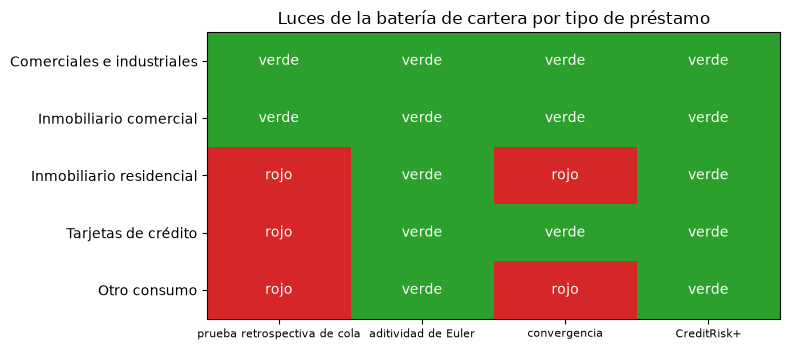

In [14]:
# Dibujar las luces de las cuatro pruebas para los cinco tipos de préstamo como una grilla de colores
from matplotlib.colors import ListedColormap

codes = {"green": 0, "amber": 1, "red": 2}
matrix = np.array([[codes[v] for v in lights[key]] for key in NAMES])
test_labels = ["prueba retrospectiva de cola", "aditividad de Euler", "convergencia", "CreditRisk+"]

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.imshow(matrix, cmap=ListedColormap(["tab:green", "tab:orange", "tab:red"]), vmin=0, vmax=2, aspect="auto")
ax.set_xticks(range(4), test_labels, fontsize=8)
ax.set_yticks(range(len(NAMES)), list(NAMES.values()))
for (i, j), value in np.ndenumerate(matrix):
    ax.text(j, i, LIGHTS[list(codes)[value]], ha="center", va="center", color="white")
ax.set_title("Luces de la batería de cartera por tipo de préstamo")
fig.tight_layout()
plt.show()

Dos columnas son todas verdes: la aditividad de Euler y la recursión de CreditRisk+ pasan para todos los tipos de préstamo, como debe hacerlo un motor correcto. Son pruebas de consistencia, y su verde dice que la implementación es coherente, no que el modelo sea correcto. Las columnas informativas son las otras dos. La prueba retrospectiva de cola es roja para el inmobiliario residencial, las tarjetas de crédito y otro consumo y verde para los dos tipos comerciales; la prueba de convergencia es roja para el residencial y otro consumo. Un validador que lea la grilla miraría primero las celdas rojas, y recordaría que las pruebas retrospectivas rojas pertenecen a los tipos de préstamo cuya ventana de ajuste no tenía una crisis. La grilla muestra luces, no magnitudes, así que los números de cada celda están en la tabla de arriba.

## Resultados

**Respuesta:** cada prueba rechaza el caso construido para estar equivocado y acepta el construido para estar correcto: dos años de seis sobre el cuantil ajustado ponen en rojo la prueba retrospectiva de cola (p = 0,0015), una varianza Gamma 50% demasiado alta da una distancia de Kolmogorov de 0,0668 y un valor p de 0, una estimación a 3,5 errores estándar del ancla es roja (p = 0,0005), y la prueba de correlación de máxima verosimilitud rechaza una correlación verdadera el 5,25% de las veces con 22 años frente a 18,5% del estimador de momentos; en los cinco tipos de préstamo la prueba retrospectiva de cola es roja para el residencial, las tarjetas de crédito y otro consumo.

- **La prueba retrospectiva de cola necesita dos años para rechazar al 99%, y los ajustes reales muestran el rango.** Con seis años de evaluación, ningún año sobre el cuantil 99% ajustado da p = 1,0 (verde), un año da p = 0,0585, todavía verde porque está sobre 0,05, y dos años dan p = 0,0015 (rojo). En los años de evaluación reales el ajuste comercial e industrial no tiene ninguno sobre el cuantil (p = 1,0, verde) y el ajuste residencial tiene 5 de 6 (p = 6e-10, rojo). La prueba es una puerta sobre el ajuste frente a los años que lo siguieron, y es la única de las cinco que se encuentra con resultados observados.
- **La prueba de convergencia aprueba o reprueba una cartera pequeña, no un modelo.** Una estimación movida 0,5 errores estándar sigue verde (p = 0,62), con 2,3 es ámbar (p = 0,021) y con 3,5 roja (p = 0,0005); un error estándar cero devuelve `not_evaluated` y ningún número. En las filas versionadas la cartera residencial es roja con z = +23,4 y otro consumo con z = +7,7, mientras comercial e industrial (z = -0,5), inmobiliario comercial (z = -1,5) y tarjetas de crédito (z = +1,3) son verdes. El notebook no prueba por qué ocurren los dos rojos; muestra solo que la comprobación de 5.000 nombres no alcanza el límite de la cartera grande con su PD y correlación, y un rojo aquí no dice que el motor esté equivocado.
- **Una tolerancia es parte del resultado.** Las contribuciones al ES suman el total exactamente (brecha 0, verde). Una contribución inflada en 0,5% deja una brecha de 0,0028, verde con la tolerancia de 0,01; inflada en 2% la brecha es 0,0111, roja. La misma brecha relativa de 1e-4 es verde con la tolerancia del VaR de 0,01 y roja con la tolerancia del ES de 1e-6. Un total cero devuelve `not_evaluated`. Una fila de Euler en verde significa entonces que la asignación suma hasta la tolerancia declarada, nada más.
- **La prueba de la recursión ve un modelo equivocado y una probabilidad negativa.** La recursión correcta contra su propia muestra tiene D = 0,00398 y p = 0,084 (verde). Una varianza Gamma 50% demasiado alta da D = 0,0668 y un valor p de 0 (rojo). Una entrada puesta en -1e-6 deja D y p sin cambio y la luz se pone roja, porque la regla marca en rojo cualquier probabilidad negativa sea cual sea el valor p.
- **La prueba de correlación de máxima verosimilitud tiene el tamaño correcto y poca potencia.** En el simulador con 22 años la prueba de máxima verosimilitud de rho = 0,12 rechaza el 5,25% de las veces cuando es verdadera (error estándar 1,1 puntos, intervalo de Wilson 3,5% a 7,9%, p = 0,82, verde) y la prueba de momentos rechaza el 18,5% de las veces (intervalo 15,0% a 22,6%, p = 3e-35, rojo). Con 40 años los tamaños son 6,0% y 13,0%. Un validador que rechaza una correlación con el intervalo de momentos se equivoca cerca de una vez de cada cinco cuando la correlación es verdadera.
- **Ninguna prueba tiene mucha potencia contra sus vecinas.** Con 22 años la prueba de máxima verosimilitud rechaza una correlación verdadera de 0,10 solo el 15% de las veces y de 0,14 solo el 7,5%; sobre la nula nunca llega a 80% con 22 años (72,5% con 0,24). Con 40 años llega a 77,5% con 0,20 y a 96,8% con 0,24. La prueba de momentos, que tiene sesgo hacia abajo, casi nunca rechaza correlaciones sobre 0,12 (4,8% a 8,7% de 0,16 a 0,24 con 22 años). De las 11 celdas de potencia con 22 años, la prueba de máxima verosimilitud es verde en 2, ámbar en 3 y roja en 6.
- **Leer juntos los cinco tipos de préstamo.** Las doce filas de aditividad de Euler de cada tipo de préstamo y la fila de CreditRisk+ son todas verdes: son puertas de consistencia que un motor correcto pasa, y no pueden decirle a un validador que el modelo está equivocado. La prueba retrospectiva de cola es roja para el residencial, las tarjetas de crédito y otro consumo y verde para los dos tipos comerciales, y esa separación, no las filas verdes, es la evidencia sobre las correlaciones ajustadas del notebook 02.

Lo que este notebook no muestra: un análisis de potencia de la propia prueba retrospectiva de cola (seis años no pueden tener mucha), el tamaño de las otras cuatro pruebas, ni el efecto de años dependientes sobre cualquiera de ellas.

## Resumen

- La batería de cartera tiene cinco pruebas: la prueba retrospectiva de cola (binomial sobre años sobre un cuantil ajustado), la prueba de convergencia de Monte Carlo (z frente a un ancla analítica), la aditividad de Euler (una suma dentro de una tolerancia), la recursión de CreditRisk+ frente a Monte Carlo (distancia de Kolmogorov, roja con una entrada negativa) y el tamaño y la potencia de un estimador de correlación.
- Cada una devuelve un `TestResult` con su hipótesis nula, sus parámetros y una luz bajo puertas de Contraste; un resultado que no se puede evaluar es `not_evaluated`, nunca un número.
- Las pruebas de consistencia las aprueba un motor correcto, y la prueba retrospectiva de cola es la que se encuentra con los resultados y separa los tipos de préstamo.
- La prueba de correlación de máxima verosimilitud tiene el tamaño correcto y poca potencia con 22 años; la prueba de momentos rechaza de más en la nula y casi nunca rechaza sobre ella.

**Qué probar a continuación.** Planta tu propio defecto: mueve un año de la prueba retrospectiva de cola, cambia la tolerancia de la prueba de aditividad, o dale a `crp_recursion_vs_mc` otro largo de grilla, y mira qué prueba se pone en rojo primero. Luego lee el notebook 07 para la literatura publicada en que estas pruebas se ubican.

## Referencias

- Wilson, E. B. (1927), Probable inference, the law of succession, and statistical inference, Journal of the American Statistical Association 22(158):209-212. https://doi.org/10.1080/01621459.1927.10502953
- Tasche, D. (2008), Capital allocation to business units and sub-portfolios: the Euler principle, arXiv 0708.2542. https://arxiv.org/abs/0708.2542
- Haaf, H., Reiss, O. y Schoenmakers, J. (2004), Numerically stable computation of CreditRisk+, Journal of Risk 6(4):1-10. https://doi.org/10.21314/jor.2004.097
- Gordy, M. B. (2003), A risk-factor model foundation for ratings-based bank capital rules, Journal of Financial Intermediation 12(3):199-232. https://doi.org/10.1016/S1042-9573(03)00040-8
- Board of Governors of the Federal Reserve System, Charge-off and delinquency rates on loans and leases at commercial banks, table chgallsa (public domain; licence class mirror-allowed). https://www.federalreserve.gov/releases/chargeoff/chgallsa.htm
- Vasicek, O. (2002), Loan portfolio value, Risk, December 2002, 160-162.
- Kolmogorov, A. (1933) and Smirnov, N. (1948), the Kolmogorov distance and its asymptotic law, as cited by the engine's `validation.portfolio` module.
- Persisted research dossier 05 of this product (the validation of an economic capital model), section G.5, and dossier 04, section C.4.
- The engine's contract for these functions: `docs/contracts/engine/` of this repository.